In [1]:
import nltk
import numpy as np
import matplotlib.pyplot as plt
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD

In [2]:
wordnet_lemmatizer = WordNetLemmatizer()

In [3]:
titles = [line.rstrip() for line in open('all_book_titles.txt')]

In [4]:
stops = set(stopwords.words('english'))

In [5]:
# great example of domain-specific stopwords
stops = stops.union({
  'introduction', 'edition', 'series', 'application',
  'approach', 'card', 'access', 'package', 'plus', 'etext',
  'brief', 'vol', 'fundamental', 'guide', 'essential', 'printed',
  'third', 'second', 'fourth', 'volume'})

In [6]:
def my_tokenizer(s):
    # downcase
    s = s.lower()

    # split string into words (tokens)
    tokens = nltk.tokenize.word_tokenize(s)

    # remove short words, they're probably not useful
    tokens = [t for t in tokens if len(t) > 2]

    # put words into base form
    tokens = [wordnet_lemmatizer.lemmatize(t) for t in tokens]

    # remove stopwords
    tokens = [t for t in tokens if t not in stops]

    # remove any digits, i.e. "3rd edition"
    tokens = [t for t in tokens if not any(c.isdigit() for c in t)]

    return tokens

In [7]:
vectorizer = CountVectorizer(
    binary=True,
    tokenizer=my_tokenizer,
    token_pattern=None
)

In [8]:
X = vectorizer.fit_transform(titles)

In [9]:
# create index -> word map for plotting later

# conceptually what we want to do
# index_word_map = [None] * len(vectorizer.vocabulary_)
# for word, index in vectorizer.vocabulary_.items():
#     index_word_map[index] = word

# but it's already stored in the count vectorizer
index_word_map = vectorizer.get_feature_names_out()

In [10]:
# transpose X to make rows = terms, cols = documents
X = X.T

In [11]:
svd = TruncatedSVD()
Z = svd.fit_transform(X)

In [12]:
import plotly.express as px

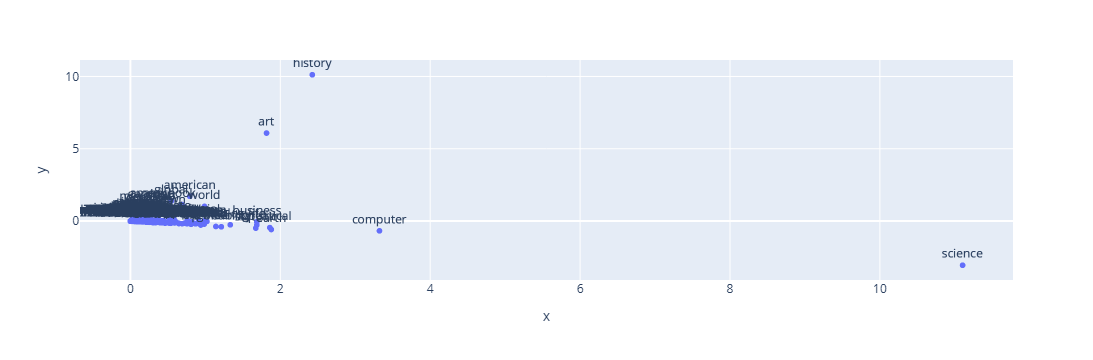

In [13]:
fig = px.scatter(
x=Z[:, 0],
y=Z[:, 1],
text=index_word_map,
size_max=60
)
fig.update_traces(textposition='top center')
fig.show()

![](https://deeplearningcourses.com/notebooks_v3_pxl?sc=N3y7GKxUH16CxQS403JQ2A&n=Latent+Semantic+Analysis+CountVectorizer)